# Data Preprocessing

## Data Analysis stage
Here, no trace file will be opened to read them, only logs and other external data will be read, and a manifest file will be created for the captured data.

In [1]:
import sys
sys.path.append("..")

from utils import build_manifest_csv, parse_tracer_log, filter_session_lines
import pandas as pd

### Set the path and session window for log file

In [2]:
LOG_PATH = "../logs/malditectist_v2.log"
OUTPUT_CSV = "../sandbox/data-e2/manifest.csv"
SESSION_START = "2026-07-18 20:00:56"
SESSION_END = "2026-07-19 08:47:38"

### Build the manifest file

In [3]:
import os

if os.path.exists(LOG_PATH):
    result = build_manifest_csv(LOG_PATH, OUTPUT_CSV, 
                                session_start=SESSION_START, session_end=SESSION_END)
    
    print(f"Finished writing {result['rows']} rows to {OUTPUT_CSV}")
    
    mins = result["duration_sec"] / 60
    
    print(f"Session Window: {result['start_ts']} - {result['end_ts']} ({mins:.1f} min)")

Finished writing 260 rows to ../sandbox/data-e2/manifest.csv
Session Window: 2026-07-18 20:00:56 - 2026-07-19 08:47:38 (766.7 min)


### Check the created manifest file

In [4]:
df = pd.read_csv(OUTPUT_CSV)
df.head(10)

,index,total,filename,timestamp_start,timestamp_end,duration_sec,opcode_count,exit_reason,exit_code,max_size_hit,raw_line_count
0,1,260,GommeHD.net-Java-API-2.2.0-jar-with-dependenci...,2026-07-18 20:00:56,2026-07-18 20:04:19,203,263246339,size_limit,NaN,True,12
1,2,260,abbot-0.13.0.jar,2026-07-18 20:04:19,2026-07-18 20:07:31,192,250721862,size_limit,NaN,True,12
2,3,260,activecluster-4.0.2.jar,2026-07-18 20:07:31,2026-07-18 20:10:15,164,192722442,exit_code_1,1.0,False,11
3,4,260,activemq-4.0-M1.jar,2026-07-18 20:10:15,2026-07-18 20:13:36,201,253984851,size_limit,NaN,True,12
4,5,260,activemq-all-6.2.6.jar,2026-07-18 20:13:36,2026-07-18 20:16:58,202,249490122,size_limit,NaN,True,12
5,6,260,activemq-axis-2.1.jar,2026-07-18 20:16:58,2026-07-18 20:19:52,174,189270633,exit_code_1,1.0,False,11
6,7,260,activemq-container-3.2-M1.jar,2026-07-18 20:19:52,2026-07-18 20:22:46,174,190134537,exit_code_1,1.0,False,11
7,8,260,activemq-core-4.0-M1.jar,2026-07-18 20:22:46,2026-07-18 20:26:03,197,224632393,exit_code_1,1.0,False,11
8,9,260,activemq-gbean-3.2.4.jar,2026-07-18 20:26:03,2026-07-18 20:28:48,165,189444110,exit_code_1,1.0,False,11
9,10,260,activemq-gbean-g1_1-3.2.4.jar,2026-07-18 20:28:48,2026-07-18 20:31:41,173,191400058,exit_code_1,1.0,False,11


In [5]:
print(f"Total rows: {len(df)}")
print("\nExit Reasons Summary")
print(df["exit_reason"].value_counts(dropna=False))

print(f"\nRows with no opcode code counts: {df['opcode_count'].isna().sum()}")
print(f"Rows with max_size_hit = True: {df['max_size_hit'].sum()}")

Total rows: 260

Exit Reasons Summary
exit_reason
exit_code_1      159
size_limit        70
natural_exit      28
exit_code_255      3
Name: count, dtype: int64

Rows with no opcode code counts: 0
Rows with max_size_hit = True: 70


### Opcode counts and duration analysis

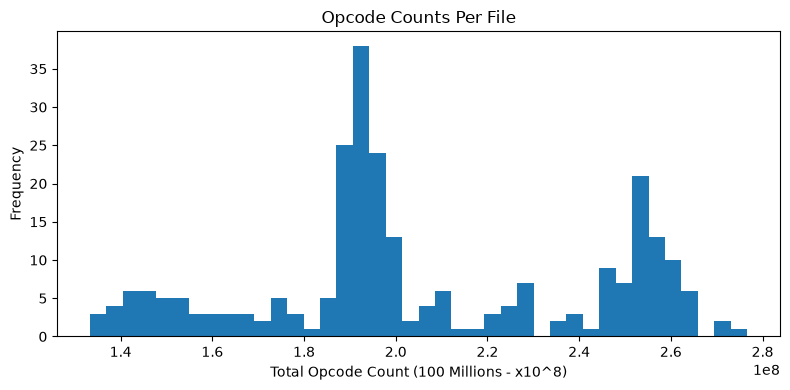

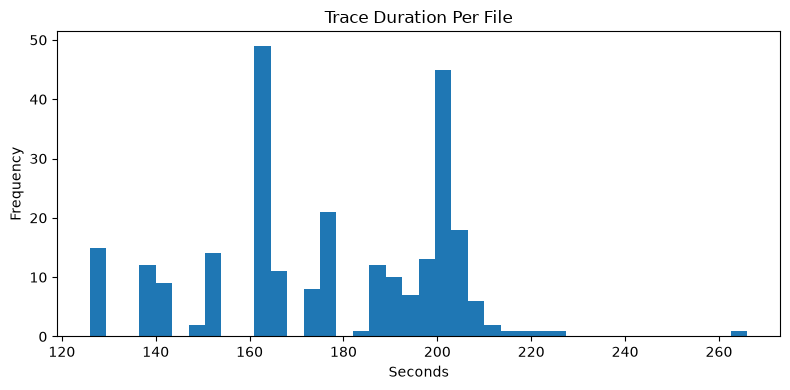

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
df["opcode_count"].dropna().plot(kind="hist", bins=40)
plt.title("Opcode Counts Per File")
plt.xlabel("Total Opcode Count (100 Millions - x10^8)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
df["duration_sec"].dropna().plot(kind="hist", bins=40)
plt.title("Trace Duration Per File")
plt.xlabel("Seconds")
plt.tight_layout()
plt.show()

Manifest file only contains the above finalized info. This can analyze the distribution of these values to understand the characteristics of the captured data. Next step is to more Exploratory Data Analysis (EDA), which also includes Feature Engineering (FE).